# putEMG: EDA

Exploratory data analysis of the putEMG gesture recordings.

1. Imports and device
2. Settings
3. List the files
4. Participants
5. Load one recording
6. Labels
7. Noise check
8. Signal strength (RMS) per gesture
9. Channel correlation
10. Another day and another person
11. All recordings

## 1. Imports and device
The heavy maths (RMS, correlation) runs on the GPU if there is one, otherwise on the CPU. Reading files and drawing plots always happen on the CPU.

In [59]:
# Run this once if a package is missing:
# !pip install pandas tables matplotlib scipy
# !pip install torch --index-url https://download.pytorch.org/whl/cu126

import os, glob
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'   # stops a kernel crash when PyTorch and Anaconda load the same library

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.signal import welch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Using: cuda
GPU: NVIDIA GeForce RTX 3070


## 2. Settings

In [60]:
DATA_DIR = r"H:\pp\putEMG\Data-HDF5"
PARTICIPANTS_FILE = r"H:\pp\putEMG\putEMG-participants.csv"

FS = 5120
LABEL_COL = 'TRAJ_GT'    # the gesture the subject really made (TRAJ_1 is the gesture they were asked to make)

# what the label numbers mean (from the dataset page)
GESTURES = {-1: 'relax', 0: 'idle', 1: 'fist', 2: 'flexion', 3: 'extension',
            6: 'pinch index', 7: 'pinch middle', 8: 'pinch ring', 9: 'pinch small'}

# 24 channels: 1-8 elbow, 9-16 middle, 17-24 wrist
EMG_COLS = ['EMG_' + str(i) for i in range(1, 25)]

print('Data folder:', DATA_DIR)
print('Participants file:', PARTICIPANTS_FILE)
print('Sampling rate:', FS, 'Hz')
print('Label column:', LABEL_COL)
print('Gestures:', GESTURES)
print('EMG channels:', len(EMG_COLS), '(' + EMG_COLS[0], 'to', EMG_COLS[-1] + ')')

Data folder: H:\pp\putEMG\Data-HDF5
Participants file: H:\pp\putEMG\putEMG-participants.csv
Sampling rate: 5120 Hz
Label column: TRAJ_GT
Gestures: {-1: 'relax', 0: 'idle', 1: 'fist', 2: 'flexion', 3: 'extension', 6: 'pinch index', 7: 'pinch middle', 8: 'pinch ring', 9: 'pinch small'}
EMG channels: 24 (EMG_1 to EMG_24)


## 3. List the files
The folder also holds `emg_force` files. They have no gesture labels, so only the `emg_gestures` files are used.

In [61]:
files = sorted(glob.glob(os.path.join(DATA_DIR, 'emg_gestures-*.hdf5')))
print('Number of files:', len(files))

# Filenames look like: emg_gestures-03-repeats_long-2018-05-11-11-05-00-695.hdf5
file_info = pd.DataFrame({'path': files})
file_info['name'] = file_info['path'].apply(os.path.basename)
file_info['subject'] = file_info['name'].apply(lambda x: x.split('-')[1])
file_info['trajectory'] = file_info['name'].apply(lambda x: x.split('-')[2])
file_info['date'] = file_info['name'].apply(lambda x: '-'.join(x.split('-')[3:6]))
file_info[['name', 'subject', 'trajectory', 'date']].head(6)

Number of files: 264


,name,subject,trajectory,date
0,emg_gestures-03-repeats_long-2018-05-11-11-05-...,03,repeats_long,2018-05-11
1,emg_gestures-03-repeats_long-2018-06-14-12-32-...,03,repeats_long,2018-06-14
2,emg_gestures-03-repeats_short-2018-05-11-11-15...,03,repeats_short,2018-05-11
3,emg_gestures-03-repeats_short-2018-06-14-12-43...,03,repeats_short,2018-06-14
4,emg_gestures-03-sequential-2018-05-11-11-10-50...,03,sequential,2018-05-11
5,emg_gestures-03-sequential-2018-06-14-12-38-43...,03,sequential,2018-06-14


In [62]:
# Every subject should have 2 recording days x 3 trajectories = 6 files
print('Subjects:', file_info['subject'].nunique())
print('Files per subject:', file_info.groupby('subject').size().unique())
print('Recording days per subject:', file_info.groupby('subject')['date'].nunique().unique())
print(file_info['trajectory'].value_counts())

Subjects: 44
Files per subject: [6]
Recording days per subject: [2]
trajectory
repeats_long     88
repeats_short    88
sequential       88
Name: count, dtype: int64


## 4. Participants
The CSV uses semicolons (`;`) as separators.

In [63]:
participants = pd.read_csv(PARTICIPANTS_FILE, sep=';', dtype={'ID': str})
participants = participants.loc[:, ~participants.columns.str.contains('Unnamed')]
print(participants.shape)
print('Recorded subjects missing from this table:', sorted(set(file_info['subject']) - set(participants['ID'])))
print('Dominant hand:', participants['Dominant hand [R/L]'].value_counts().to_dict())
participants.head()

(44, 18)
Recorded subjects missing from this table: []
Dominant hand: {'R': 39, 'L': 5}


,ID,Gender [F/M],Age [years],Height [cm],Weight [kg],Forearm diameter (elbow band) [cm],Forearm diameter (wrist band) [cm],Dominant hand [R/L],Movement/muscle disorders,Neurological diseases,Skin diseases,Contact allergies (type),Contact allergies [-/(W)eek/(M)oderate/(S)trong],Sport activity (type),Sport activity [-/(R)arely/(O)once a week/(T)wice a week/(E)very day],Tobacco [-/(R)arely/(O)nce a week/(E)very day],Experiment 1,Experiment 2
0,03,M,37,173,78.0,27.0,25.0,R,-,-,-,-,-,?,T,-,11.05.2018,15.05.2018
1,04,M,37,191,120.0,30.0,28.0,R,-,-,-,-,-,"jogging, cardio",O,-,28.03.2018,18.06.2018
2,05,M,21,173,84.0,25.5,23.0,R,-,-,-,-,-,-,-,-,4.04.2018,20.04.2018
3,06,M,21,185,80.0,29.5,26.5,R,-,-,-,"mites, pollen",M,"climbing, swimming, squash",T,-,4.04.2018,16.04.2018
4,07,M,24,183,98.0,30.0,27.0,R,-,-,-,-,-,"gym, squash",T,-,4.04.2018,11.05.2018


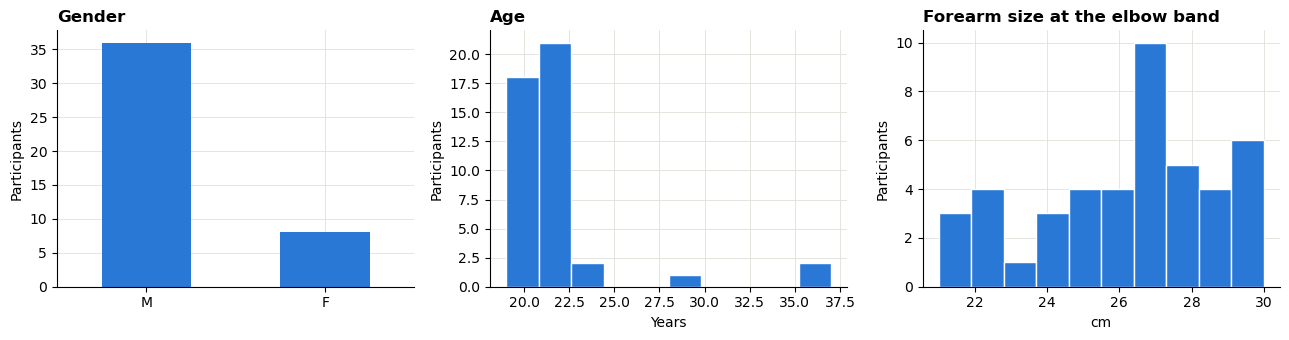

In [64]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))

participants['Gender [F/M]'].value_counts().plot(kind='bar', ax=ax[0], title='Gender', rot=0)
ax[0].set_xlabel('')
ax[0].set_ylabel('Participants')

participants['Age [years]'].plot(kind='hist', bins=10, ax=ax[1], title='Age', edgecolor='white')
ax[1].set_xlabel('Years')
ax[1].set_ylabel('Participants')

participants['Forearm diameter (elbow band) [cm]'].plot(kind='hist', bins=10, ax=ax[2], title='Forearm size at the elbow band', edgecolor='white')
ax[2].set_xlabel('cm')
ax[2].set_ylabel('Participants')

plt.tight_layout()
plt.show()

## 5. Load one recording

In [65]:
df = pd.read_hdf(files[0])
print(os.path.basename(files[0]))
print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head()

emg_gestures-03-repeats_long-2018-05-11-11-05-00-695.hdf5
Shape: (1746944, 32)
Columns: ['EMG_1', 'EMG_2', 'EMG_3', 'EMG_4', 'EMG_5', 'EMG_6', 'EMG_7', 'EMG_8', 'EMG_9', 'EMG_10', 'EMG_11', 'EMG_12', 'EMG_13', 'EMG_14', 'EMG_15', 'EMG_16', 'EMG_17', 'EMG_18', 'EMG_19', 'EMG_20', 'EMG_21', 'EMG_22', 'EMG_23', 'EMG_24', 'TRAJ_1', 'type', 'subject', 'trajectory', 'date_time', 'TRAJ_GT_NO_FILTER', 'VIDEO_STAMP', 'TRAJ_GT']


,EMG_1,EMG_2,EMG_3,EMG_4,EMG_5,EMG_6,EMG_7,EMG_8,EMG_9,EMG_10,...,EMG_23,EMG_24,TRAJ_1,type,subject,trajectory,date_time,TRAJ_GT_NO_FILTER,VIDEO_STAMP,TRAJ_GT
-0.018603,1.0,1.0,1.0,0.0,-2.0,-4.0,1.0,1.0,2.0,-1.0,...,3.0,3.0,-1.0,emg_gestures,3.0,repeats_long,2018-05-11 11:05:00.695,-1.0,-2.157148,-1.0
-0.018408,4.0,4.0,4.0,2.0,0.0,-2.0,4.0,4.0,4.0,2.0,...,4.0,4.0,-1.0,emg_gestures,3.0,repeats_long,2018-05-11 11:05:00.695,-1.0,-2.156953,-1.0
-0.018213,12.0,12.0,11.0,9.0,8.0,3.0,13.0,11.0,11.0,10.0,...,7.0,7.0,-1.0,emg_gestures,3.0,repeats_long,2018-05-11 11:05:00.695,-1.0,-2.156758,-1.0
-0.018018,19.0,17.0,17.0,14.0,14.0,7.0,19.0,17.0,16.0,16.0,...,10.0,9.0,-1.0,emg_gestures,3.0,repeats_long,2018-05-11 11:05:00.695,-1.0,-2.156563,-1.0
-0.017823,18.0,17.0,17.0,15.0,14.0,7.0,19.0,17.0,15.0,17.0,...,10.0,9.0,-1.0,emg_gestures,3.0,repeats_long,2018-05-11 11:05:00.695,-1.0,-2.156368,-1.0


In [66]:
print('Missing values:', df.isnull().sum().sum())
print('Recording length (seconds):', len(df) / FS)
print('EMG range: %d to %d ADC counts' % (df[EMG_COLS].min().min(), df[EMG_COLS].max().max()))

Missing values: 0
Recording length (seconds): 341.2
EMG range: -716 to 795 ADC counts


In [67]:
emg = torch.tensor(df[EMG_COLS].values, dtype=torch.float32, device=device)
labels = torch.tensor(df[LABEL_COL].values, device=device)
print(emg.shape, 'on', emg.device)

stats = pd.DataFrame({
    'mean': emg.mean(dim=0).cpu().numpy(),
    'std': emg.std(dim=0).cpu().numpy(),
    'min': emg.min(dim=0).values.cpu().numpy(),
    'max': emg.max(dim=0).values.cpu().numpy(),
}, index=EMG_COLS)
stats.astype(float).round(1)

torch.Size([1746944, 24]) on cuda:0


,mean,std,min,max
EMG_1,-0.9,35.2,-541.0,795.0
EMG_2,-1.1,20.8,-409.0,436.0
EMG_3,-1.2,18.2,-422.0,406.0
EMG_4,-1.1,15.2,-188.0,301.0
EMG_5,-1.1,16.3,-181.0,312.0
EMG_6,-1.1,28.2,-226.0,505.0
EMG_7,-1.1,19.0,-213.0,278.0
EMG_8,-1.1,16.8,-172.0,291.0
EMG_9,-1.0,34.3,-716.0,435.0
EMG_10,-0.9,19.0,-291.0,342.0


## 6. Labels
How much time is spent in each gesture, and does the real gesture match what the subject was asked to do?

relax            42.7
idle            182.3
fist             16.9
flexion          16.0
extension        17.0
pinch index      17.5
pinch middle     15.7
pinch ring       15.5
pinch small      17.5
Name: count, dtype: float64


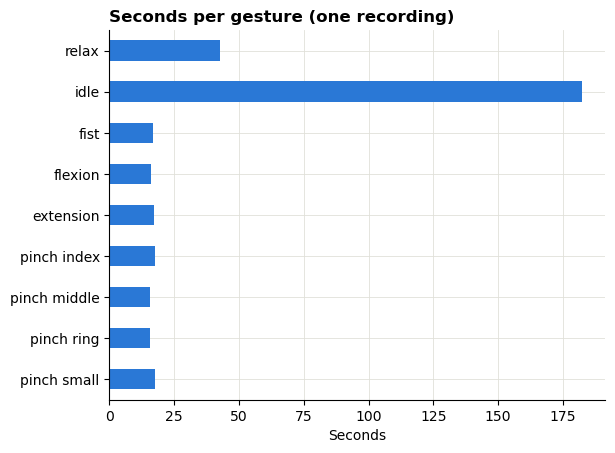

In [68]:
seconds = df[LABEL_COL].value_counts().sort_index() / FS
seconds.index = [GESTURES[c] for c in seconds.index]
print(seconds.round(1))

seconds.plot(kind='barh', title='Seconds per gesture (one recording)')
plt.gca().invert_yaxis()
plt.xlabel('Seconds')
plt.show()

In [69]:
change = np.flatnonzero(np.diff(df[LABEL_COL].values)) + 1
starts = np.r_[0, change]
ends = np.r_[change, len(df)]
segments = pd.DataFrame({'gesture': [GESTURES[c] for c in df[LABEL_COL].values[starts]],
                         'seconds': (ends - starts) / FS})
segments.groupby('gesture')['seconds'].agg(['count', 'min', 'median', 'max']).round(2)

,count,min,median,max
gesture,,,,
extension,8,0.71,2.39,3.35
fist,8,1.07,2.09,3.18
flexion,8,1.04,1.86,3.15
idle,62,2.34,2.88,3.99
pinch index,8,1.17,2.16,3.25
pinch middle,8,0.97,1.71,3.11
pinch ring,8,0.94,1.64,3.11
pinch small,8,1.11,2.16,3.28
relax,11,0.81,4.99,5.04


In [70]:
match = (df['TRAJ_1'] == df[LABEL_COL]).mean()
print('The real gesture equals the prompt in %.1f%% of the samples' % (100 * match))

table = pd.crosstab(df['TRAJ_1'], df[LABEL_COL], normalize='index') * 100
table.index = ['asked: ' + GESTURES[c] for c in table.index]
table.columns = [GESTURES[c] for c in table.columns]
table.round(1)

The real gesture equals the prompt in 87.7% of the samples


,relax,idle,fist,flexion,extension,pinch index,pinch middle,pinch ring,pinch small
asked: relax,99.7,0.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0
asked: idle,0.7,87.5,1.9,1.8,2.5,1.4,1.5,1.2,1.5
asked: fist,0.0,17.1,82.9,0.0,0.0,0.0,0.0,0.0,0.0
asked: flexion,0.0,21.0,0.0,79.0,0.0,0.0,0.0,0.0,0.0
asked: extension,0.0,23.1,0.0,0.0,76.9,0.0,0.0,0.0,0.0
asked: pinch index,0.0,6.8,0.0,0.0,0.0,93.2,0.0,0.0,0.0
asked: pinch middle,5.9,13.5,0.0,0.0,0.0,0.0,80.7,0.0,0.0
asked: pinch ring,4.1,13.2,0.0,0.0,0.0,0.0,0.0,82.7,0.0
asked: pinch small,0.0,8.9,0.0,0.0,0.0,0.0,0.0,0.0,91.1


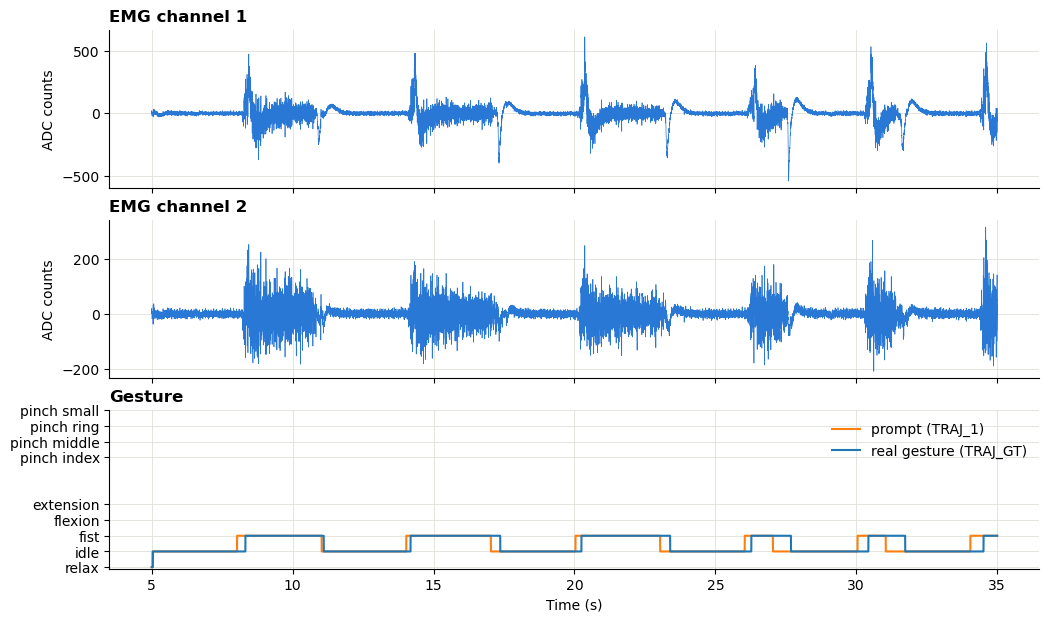

In [71]:
start, stop = 5 * FS, 35 * FS
t = np.arange(start, stop) / FS

fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

ax[0].plot(t, df['EMG_1'].values[start:stop], linewidth=0.5)
ax[0].set_title('EMG channel 1')
ax[0].set_ylabel('ADC counts')

ax[1].plot(t, df['EMG_2'].values[start:stop], linewidth=0.5)
ax[1].set_title('EMG channel 2')
ax[1].set_ylabel('ADC counts')

ax[2].plot(t, df['TRAJ_1'].values[start:stop], color='tab:orange', label='prompt (TRAJ_1)')
ax[2].plot(t, df[LABEL_COL].values[start:stop], color='tab:blue', label='real gesture (TRAJ_GT)')
ax[2].set_yticks(list(GESTURES.keys()))
ax[2].set_yticklabels(list(GESTURES.values()))
ax[2].set_title('Gesture')
ax[2].set_xlabel('Time (s)')
ax[2].legend(loc='upper right')

plt.show()

## 7. Noise check
While idle the muscles are relaxed, so what is left in the signal is noise. Sharp spikes in the power spectrum are interference from the power line and other equipment.

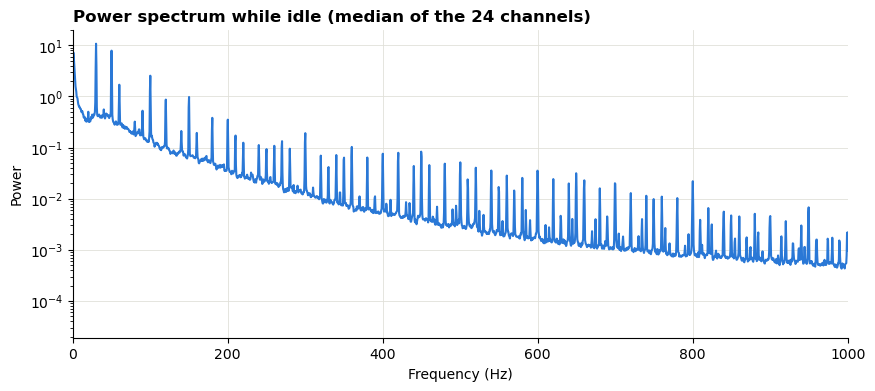

In [72]:
idle_rows = (df[LABEL_COL] == 0).values
freqs, power = welch(df[EMG_COLS].values[idle_rows], fs=FS, nperseg=FS * 2, axis=0)

plt.figure(figsize=(10, 4))
plt.semilogy(freqs, np.median(power, axis=1))
plt.xlim(0, 1000)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('Power spectrum while idle (median of the 24 channels)')
plt.show()

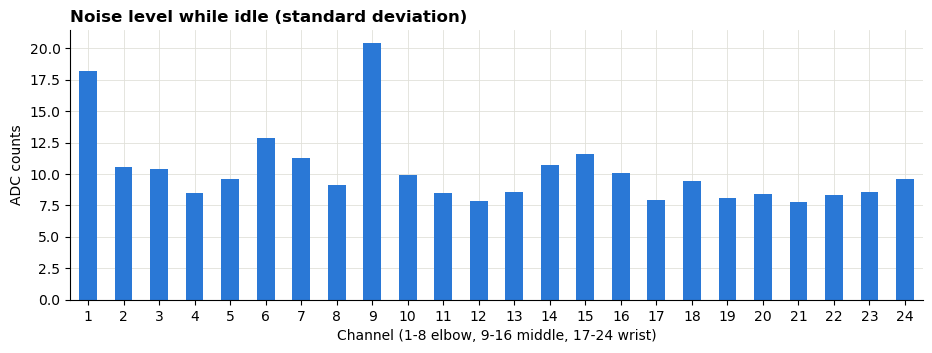

In [73]:
idle_std = df.loc[idle_rows, EMG_COLS].std()
idle_std.index = range(1, 25)

idle_std.plot(kind='bar', rot=0, figsize=(11, 3.5), title='Noise level while idle (standard deviation)')
plt.xlabel('Channel (1-8 elbow, 9-16 middle, 17-24 wrist)')
plt.ylabel('ADC counts')
plt.show()

## 8. Signal strength (RMS) per gesture
RMS measures how strong the signal is. If the gestures give different patterns across the channels, a model can likely tell them apart.

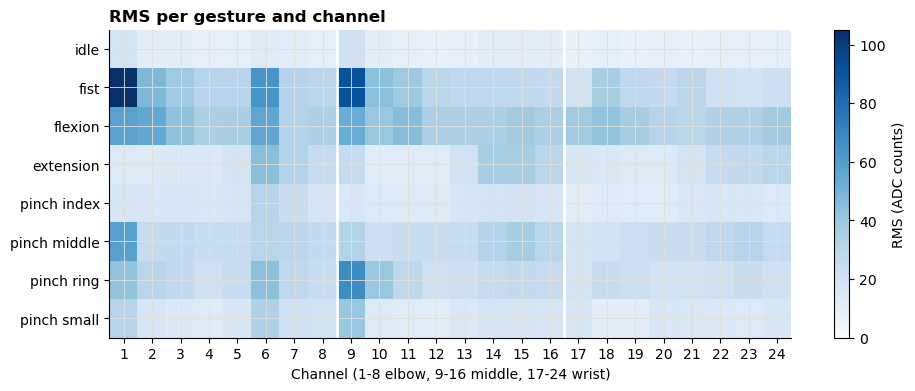

In [74]:
def gesture_rms(signal, labels):
    rms = {}
    for code in [0, 1, 2, 3, 6, 7, 8, 9]:
        part = signal[labels == code]
        rms[GESTURES[code]] = part.pow(2).mean(dim=0).sqrt().cpu().numpy()
    return pd.DataFrame(rms, index=EMG_COLS).T

rms = gesture_rms(emg, labels)

plt.figure(figsize=(11, 4))
plt.imshow(rms, aspect='auto', cmap='Blues', vmin=0)
for edge in [7.5, 15.5]:
    plt.axvline(edge, color='white', linewidth=2)
plt.colorbar(label='RMS (ADC counts)')
plt.xticks(range(24), range(1, 25))
plt.yticks(range(len(rms)), rms.index)
plt.xlabel('Channel (1-8 elbow, 9-16 middle, 17-24 wrist)')
plt.title('RMS per gesture and channel')
plt.show()

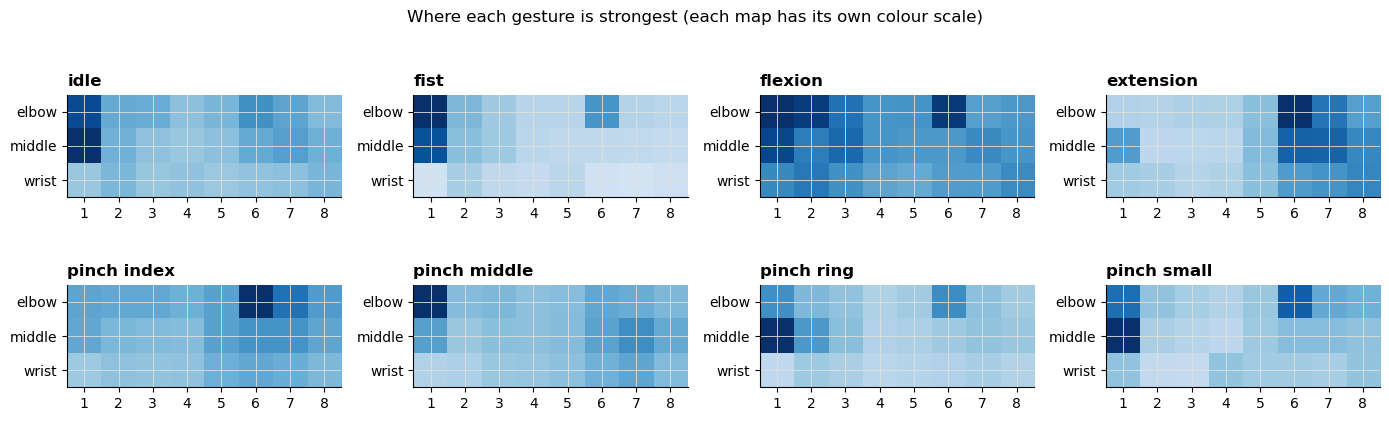

In [75]:
fig, ax = plt.subplots(2, 4, figsize=(14, 4.5))
for i, gesture in enumerate(rms.index):
    a = ax.flat[i]
    a.imshow(rms.loc[gesture].values.reshape(3, 8), cmap='Blues', vmin=0)
    a.set_title(gesture)
    a.set_xticks(range(8))
    a.set_xticklabels(range(1, 9))
    a.set_yticks(range(3))
    a.set_yticklabels(['elbow', 'middle', 'wrist'])
plt.suptitle('Where each gesture is strongest (each map has its own colour scale)')
plt.tight_layout()
plt.show()

In [76]:
strength = rms.mean(axis=1) / rms.loc['idle'].mean()
print(strength.round(1))

idle            1.0
fist            3.6
flexion         3.8
extension       2.1
pinch index     1.6
pinch middle    2.7
pinch ring      2.7
pinch small     1.7
dtype: float32


## 9. Channel correlation
Neighbouring electrodes pick up the same muscles, so their signals are similar.

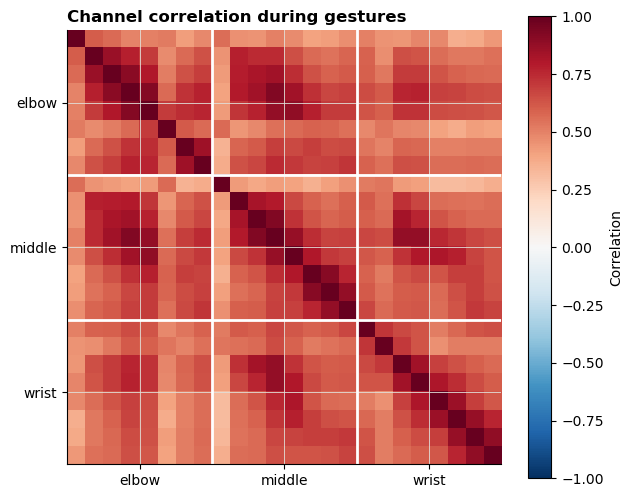

In [77]:
active = emg[labels > 0]
corr = torch.corrcoef(active.T).cpu().numpy()

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
for edge in [7.5, 15.5]:
    plt.axvline(edge, color='white', linewidth=2)
    plt.axhline(edge, color='white', linewidth=2)
plt.colorbar(label='Correlation')
plt.xticks([3.5, 11.5, 19.5], ['elbow', 'middle', 'wrist'])
plt.yticks([3.5, 11.5, 19.5], ['elbow', 'middle', 'wrist'])
plt.title('Channel correlation during gestures')
plt.show()

## 10. Another day and another person
Each subject was recorded on two days. The electrodes are never put back in exactly the same place, so the pattern changes. Here subject 03 on day 1 and day 2 is compared with subject 04 on day 1 and day 2.

In [78]:
def load_rms(path):
    d = pd.read_hdf(path)
    x = torch.tensor(d[EMG_COLS].values, dtype=torch.float32, device=device)
    y = torch.tensor(d[LABEL_COL].values, device=device)
    return gesture_rms(x, y)

# file numbers: 0 and 1 = subject 03 (day 1, day 2), 6 and 7 = subject 04 (day 1, day 2)
chosen = [0, 1, 6, 7]
titles = ['Subject 03, day 1', 'Subject 03, day 2', 'Subject 04, day 1', 'Subject 04, day 2']
for i in chosen:
    print(os.path.basename(files[i]))

tables = [rms] + [load_rms(files[i]) for i in chosen[1:]]

emg_gestures-03-repeats_long-2018-05-11-11-05-00-695.hdf5
emg_gestures-03-repeats_long-2018-06-14-12-32-53-659.hdf5
emg_gestures-04-repeats_long-2018-03-28-12-38-01-391.hdf5
emg_gestures-04-repeats_long-2018-06-18-15-02-12-970.hdf5


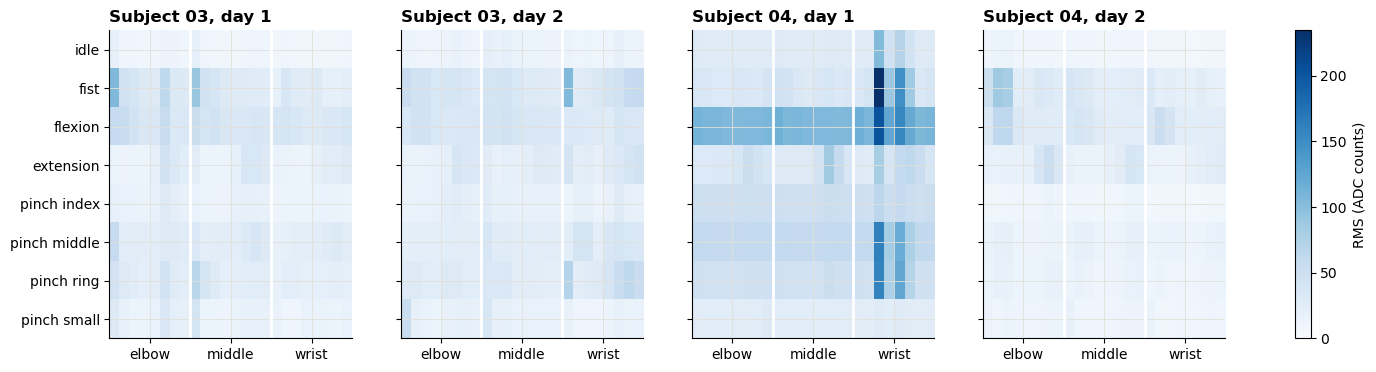

In [79]:
top = max(table.values.max() for table in tables)

fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for i in range(4):
    im = ax[i].imshow(tables[i], aspect='auto', cmap='Blues', vmin=0, vmax=top)
    for edge in [7.5, 15.5]:
        ax[i].axvline(edge, color='white', linewidth=2)
    ax[i].set_title(titles[i])
    ax[i].set_xticks([3.5, 11.5, 19.5])
    ax[i].set_xticklabels(['elbow', 'middle', 'wrist'])
ax[0].set_yticks(range(len(rms)))
ax[0].set_yticklabels(rms.index)
fig.colorbar(im, ax=ax, label='RMS (ADC counts)')
plt.show()

In [83]:

print('Same subject on the other day: subject 03 %.2f, subject 04 %.2f' % (same[0], same[1]))
print('Different subjects: average %.2f (lowest %.2f, highest %.2f)' % (np.mean(different), min(different), max(different)))

Same subject on the other day: subject 03 0.53, subject 04 0.30
Different subjects: average 0.45 (lowest 0.30, highest 0.66)


## 11. All recordings
The same checks on every recording, one file at a time: missing values and seconds per gesture. This takes about 10 minutes, mostly reading the files.

In [81]:
rows = []
for i, path in enumerate(files):
    d = pd.read_hdf(path)
    row = {'name': os.path.basename(path),
           'subject': os.path.basename(path).split('-')[1],
           'missing': int(d.isnull().sum().sum())}

    counts = d[LABEL_COL].value_counts() / FS
    for code in GESTURES:
        row[GESTURES[code]] = counts.get(code, 0)

    rows.append(row)
    if (i + 1) % 50 == 0:
        print(i + 1, 'of', len(files), 'files done')

summary = pd.DataFrame(rows)
print('Missing values in all files:', summary['missing'].sum())
summary[['name', 'missing', 'idle', 'fist']].round(2).head()

50 of 264 files done
100 of 264 files done
150 of 264 files done
200 of 264 files done
250 of 264 files done
Missing values in all files: 0


,name,missing,idle,fist
0,emg_gestures-03-repeats_long-2018-05-11-11-05-...,0,182.30,16.95
1,emg_gestures-03-repeats_long-2018-06-14-12-32-...,0,185.28,16.35
2,emg_gestures-03-repeats_short-2018-05-11-11-15...,0,139.84,13.31
3,emg_gestures-03-repeats_short-2018-06-14-12-43...,0,134.70,13.09
4,emg_gestures-03-sequential-2018-05-11-11-10-50...,0,139.67,13.01


relax           188.7
idle            667.7
fist             63.7
flexion          63.2
extension        61.3
pinch index      60.3
pinch middle     60.1
pinch ring       59.0
pinch small      60.5
dtype: float64
Total: 21.4 hours


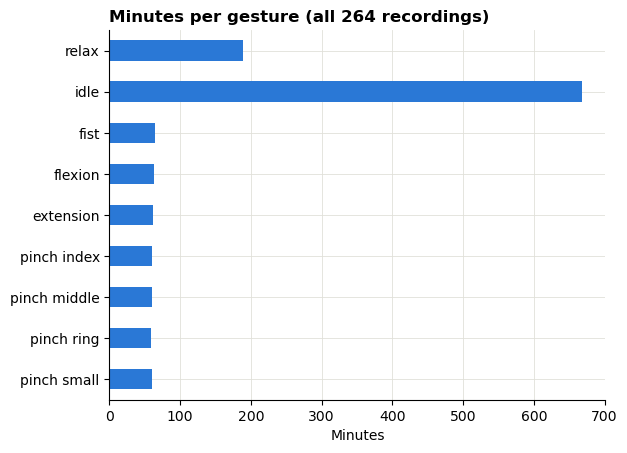

In [82]:
minutes = summary[list(GESTURES.values())].sum() / 60
print(minutes.round(1))
print('Total: %.1f hours' % (minutes.sum() / 60))

minutes.plot(kind='barh', title='Minutes per gesture (all %d recordings)' % len(summary))
plt.gca().invert_yaxis()
plt.xlabel('Minutes')
plt.show()